In [2]:
from langgraph.graph import StateGraph,START,END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from dotenv import load_dotenv
from typing import TypedDict

In [4]:
load_dotenv()

True

In [5]:
llm=ChatOpenAI(model='gpt-4o')

In [3]:
class JokeState(TypedDict):
    topic:str
    joke:str
    explaination:str

In [6]:
def generate_joke(state:JokeState):
    prompt=PromptTemplate(template="""generate a joke on below topic : {topic}""",
                          input_variables=['topic'])
    chain= prompt | llm
    response=chain.invoke({'topic':state['topic']})
    return {'joke':response.content}
    

In [7]:
def generate_explaination(state:JokeState):
    prompt=PromptTemplate(template="""explain the below shared joke : {joke}""",
                              input_variables=['joke'])
    chain= prompt | llm
    response=chain.invoke({'joke':state['joke']})
    return {'explaination':response.content}

In [8]:
graph=StateGraph(JokeState)

In [9]:
# Add Nodes

graph.add_node('generate_joke',generate_joke)
graph.add_node('generate_explaination',generate_explaination)

# Add Edges
graph.add_edge(START,'generate_joke')
graph.add_edge('generate_joke','generate_explaination')
graph.add_edge('generate_explaination',END)

In [10]:
checkpointer=InMemorySaver()

In [11]:
workflow=graph.compile(checkpointer=checkpointer)

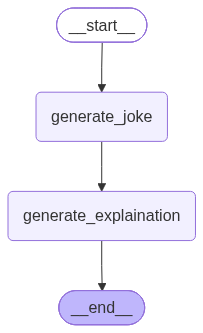

In [12]:
workflow

In [16]:
thread_id=1
config={'configurable':{'thread_id':thread_id}}

In [22]:
thread_id=2
config={'configurable':{'thread_id':thread_id}}

In [23]:
initial_state={'topic':'indian streetfood'}

In [24]:
final_state=workflow.invoke(initial_state,config=config)

In [19]:
final_state

{'topic': 'indian railways',
 'joke': "Why don't Indian Railways trains ever get lost?\n\nBecause even when they're off track, they still have chai and snacks to find their way back!",
 'explaination': 'This joke plays on a few cultural and operational aspects associated with Indian Railways.\n\n1. **Notoriety for Delays and Issues:** Indian Railways, one of the largest rail networks in the world, is often humorously criticized for delays, overcrowding, and sometimes even going off-schedule or facing other operational issues. The joke implies that trains might metaphorically "get lost" or deviate from their usual punctuality or efficiency.\n\n2. **Chai and Snacks:** The mention of "chai" (tea) and snacks is a light-hearted nod to the ubiquitous presence of food vendors and chaiwalas (tea sellers) at Indian train stations and on trains. These vendors are a quintessential part of the Indian train travel experience and highlight the vibrant, bustling nature of Indian Railways.\n\n3. **Fin

In [20]:
workflow.get_state(config=config)

StateSnapshot(values={'topic': 'indian railways', 'joke': "Why don't Indian Railways trains ever get lost?\n\nBecause even when they're off track, they still have chai and snacks to find their way back!", 'explaination': 'This joke plays on a few cultural and operational aspects associated with Indian Railways.\n\n1. **Notoriety for Delays and Issues:** Indian Railways, one of the largest rail networks in the world, is often humorously criticized for delays, overcrowding, and sometimes even going off-schedule or facing other operational issues. The joke implies that trains might metaphorically "get lost" or deviate from their usual punctuality or efficiency.\n\n2. **Chai and Snacks:** The mention of "chai" (tea) and snacks is a light-hearted nod to the ubiquitous presence of food vendors and chaiwalas (tea sellers) at Indian train stations and on trains. These vendors are a quintessential part of the Indian train travel experience and highlight the vibrant, bustling nature of Indian Ra

In [21]:
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'topic': 'indian railways', 'joke': "Why don't Indian Railways trains ever get lost?\n\nBecause even when they're off track, they still have chai and snacks to find their way back!", 'explaination': 'This joke plays on a few cultural and operational aspects associated with Indian Railways.\n\n1. **Notoriety for Delays and Issues:** Indian Railways, one of the largest rail networks in the world, is often humorously criticized for delays, overcrowding, and sometimes even going off-schedule or facing other operational issues. The joke implies that trains might metaphorically "get lost" or deviate from their usual punctuality or efficiency.\n\n2. **Chai and Snacks:** The mention of "chai" (tea) and snacks is a light-hearted nod to the ubiquitous presence of food vendors and chaiwalas (tea sellers) at Indian train stations and on trains. These vendors are a quintessential part of the Indian train travel experience and highlight the vibrant, bustling nature of Indian R

In [25]:
final_state

{'topic': 'indian streetfood',
 'joke': 'Why did the samosa break up with the jalebi?\n\nBecause it couldn’t handle the twists in their relationship!',
 'explaination': 'This joke is a play on words and makes use of the characteristics of samosas and jalebis, which are popular snacks in Indian cuisine.\n\n1. **Samosa**: A samosa is a savory pastry filled with ingredients like potatoes, peas, spices, etc., and has a triangular shape. It\'s usually known for its consistent, stable form.\n\n2. **Jalebi**: Jalebi, on the other hand, is a sweet dish made by deep-frying flour batter into circular, spiral shapes and then soaking them in sugar syrup. The key characteristic of jalebi is its twisty, spiral form.\n\nThe humor in the joke comes from the metaphorical use of the jalebi\'s physical twists to represent twists in a relationship—unexpected changes or complications. By saying the samosa couldn\'t handle the "twists," it humorously implies that a straightforward samosa struggled with the 

In [26]:
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'topic': 'indian streetfood', 'joke': 'Why did the samosa break up with the jalebi?\n\nBecause it couldn’t handle the twists in their relationship!', 'explaination': 'This joke is a play on words and makes use of the characteristics of samosas and jalebis, which are popular snacks in Indian cuisine.\n\n1. **Samosa**: A samosa is a savory pastry filled with ingredients like potatoes, peas, spices, etc., and has a triangular shape. It\'s usually known for its consistent, stable form.\n\n2. **Jalebi**: Jalebi, on the other hand, is a sweet dish made by deep-frying flour batter into circular, spiral shapes and then soaking them in sugar syrup. The key characteristic of jalebi is its twisty, spiral form.\n\nThe humor in the joke comes from the metaphorical use of the jalebi\'s physical twists to represent twists in a relationship—unexpected changes or complications. By saying the samosa couldn\'t handle the "twists," it humorously implies that a straightforward samosa

In [27]:
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'topic': 'indian streetfood', 'joke': 'Why did the samosa break up with the jalebi?\n\nBecause it couldn’t handle the twists in their relationship!', 'explaination': 'This joke is a play on words and makes use of the characteristics of samosas and jalebis, which are popular snacks in Indian cuisine.\n\n1. **Samosa**: A samosa is a savory pastry filled with ingredients like potatoes, peas, spices, etc., and has a triangular shape. It\'s usually known for its consistent, stable form.\n\n2. **Jalebi**: Jalebi, on the other hand, is a sweet dish made by deep-frying flour batter into circular, spiral shapes and then soaking them in sugar syrup. The key characteristic of jalebi is its twisty, spiral form.\n\nThe humor in the joke comes from the metaphorical use of the jalebi\'s physical twists to represent twists in a relationship—unexpected changes or complications. By saying the samosa couldn\'t handle the "twists," it humorously implies that a straightforward samosa